This script was intorduced to clarify the qeustion of how well the embedding without the velocity looks like. 

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import yaml
from scipy.sparse import issparse
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
from sklearn.manifold import trustworthiness
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

In [2]:
datasets = {
        "Pancreas_dynamical": "/mnt/volume/Johanna_Velotest/configs/pancreas_dynamic.yaml",
        "Pancreas_stochastic": "/mnt/volume/Johanna_Velotest/configs/pancreas_stochastic.yaml",
        "Dentate_gyrus": "/mnt/volume/Johanna_Velotest/configs/dentategyrus.yaml",
        "Gastrulation_erythroid": "/mnt/volume/Johanna_Velotest/configs/gastrulation.yaml",
        "Bone_marrow": "/mnt/volume/Johanna_Velotest/configs/bonemarrow.yaml",
        "PBMC": "/mnt/volume/Johanna_Velotest/configs/pbmc.yaml",
        "Covid": "/mnt/volume/Johanna_Velotest/configs/covid.yaml",
        "Retinal_development": "/mnt/volume/Johanna_Velotest/configs/retinal_development.yaml",
        "Human_HSC": "/mnt/volume/Johanna_Velotest/configs/humanHSC.yaml",
        "RPE_1": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/intestinal_organoids.yaml",
        "Hindbrain_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/hindbrain.yaml",
        "Oligodendrocyte_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/oligodendrocyte.yaml",
        "Bone_marrow_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/mouse_bonemarrow.yaml",
        "Cerebral_cortex_human": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/human_cerebral.yaml",
        "Hematopoiesis_mouse": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/mouse_hema.yaml",
        "Spermatogenisis": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/spermatogenesis.yaml",
        "Old_brain": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/old_brain.yaml",
        "Prefrontal_cortex": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/pfc.yaml",
        "Intestinal_organoids":"/mnt/volume/Johanna_Velotest/configs/noEmbedding/GSE128365.yaml",
        "Zebra_NMP": "/mnt/volume/Johanna_Velotest/configs/noEmbedding/zebra_NMP.yaml"
    }

In [4]:
def calculate_spearman(high_dim, low_dim, sample_size=1000):
    """Calculates Spearman CPD like in Kobbak (2019) using a random subset of 1.000 cells."""
    # Copied code from the papers repository
    # Sample data for pairwise distance correlation calculation
    subset = np.random.choice(high_dim.shape[0], size=sample_size, replace=False)

    # Extrace indices and handle sparse matrices in case they are sparse
    hd_subset = high_dim[subset, :]
    ld_subset = low_dim[subset, :]

    if issparse(hd_subset):
        hd_subset = hd_subset.toarray()
    if issparse(ld_subset):
        ld_subset = ld_subset.toarray()

    # Compute pairwise distances in original and embedded spaces
    d1 = pdist(hd_subset)  # Pairwise distances in high-dimensional space
    d2 = pdist(ld_subset)  # Pairwise distances in low-dimensional space

    # Calculate Spearman correlation between the pairwise distances
    rho = spearmanr(d1[:, None], d2[:, None]).correlation

    return rho

def calculate_knn(high_dim, low_dim, k=10):
    """Calculates KNN accoriding to Kobbak(2019)"""
    # Copied code from the papers repository
    # Adapt for spare matrices
    if issparse(high_dim):
        high_dim = high_dim.tocsr()
    if issparse(low_dim):
        low_dim = low_dim.tocsr()
    # Compute local nearest-neighbor indices for high-dimensional data
    nbrs1 = NearestNeighbors(n_neighbors=k).fit(high_dim)
    ind1 = nbrs1.kneighbors(return_distance=False)  # Nearest neighbor indices for X

    # Compute local nearest-neighbor indices for low-dimensional embedding
    nbrs2 = NearestNeighbors(n_neighbors=k).fit(low_dim)
    ind2 = nbrs2.kneighbors(return_distance=False)  # Nearest neighbor indices for Z

    # Calculate mean nearest-neighbor overlap (local)
    intersections = 0.0
    for i in range(high_dim.shape[0]):
        # Count intersection of nearest neighbors in original and embedded spaces
        intersections += len(set(ind1[i]) & set(ind2[i]))
    mnn = intersections / high_dim.shape[0] / k  # Normalize by total samples and neighbors
        
    return mnn

def calculate_knc(high_dim, low_dim, labels, k = 4):
    """Calculates KNC accoriding to Kobbak(2019)"""
    # Copied code from the papers repository
    # Adapt for spare matrices
    if issparse(high_dim):
        high_dim = high_dim.tocsr()
    if issparse(low_dim):
        low_dim = low_dim.tocsr()
    # Compute class centroids for high-dimensional and embedded spaces
    cl, cl_inv = np.unique(labels, return_inverse=True)  # Unique class labels and their indices
    C = cl.size  # Number of unique classes
    mu1 = np.zeros((C, high_dim.shape[1]))  # Centroids for X
    mu2 = np.zeros((C, low_dim.shape[1]))  # Centroids for Z
    for c in range(C):
        # Calculate centroids for each class in X and Z
        mu1[c, :] = np.mean(high_dim[cl_inv == c, :], axis=0)
        mu2[c, :] = np.mean(low_dim[cl_inv == c, :], axis=0)

    # Compute global nearest-neighbor indices based on class centroids
    nbrs1 = NearestNeighbors(n_neighbors=k).fit(mu1)
    ind1 = nbrs1.kneighbors(return_distance=False)  # Nearest neighbor indices for class centroids in X
    nbrs2 = NearestNeighbors(n_neighbors=k).fit(mu2)
    ind2 = nbrs2.kneighbors(return_distance=False)  # Nearest neighbor indices for class centroids in Z

    # Calculate mean nearest-neighbor overlap (global, class-based)
    intersections = 0.0
    for i in range(C):
        # Count intersection of nearest neighbors in class centroid space
        intersections += len(set(ind1[i]) & set(ind2[i]))
    knc = intersections / C / k  # Normalize by number of classes and neighbors

    return knc

In [32]:
results = {}

for name, path in datasets.items():
    print(name)
    # Calculte PCA and original values
    with open(path, "r") as f:
        config = yaml.safe_load(f)

    adata = sc.read(config['path'])
    print(adata)
    basis = config['basis']
    cluster = config['cluster']
    labels = adata.obs[cluster]
    umap = adata.obsm["X_umap"]
    if "X_tsne" not in adata.obsm:
        sc.tl.tsne(adata)
    tsne = adata.obsm['X_tsne']

    if name == 'Human_HSC':
        high_dim_data = adata.layers['matrix']
    else: 
        high_dim_data = adata.X

    results[name] = {
        "umap": {},
        "tsne": {}
    }

    results[name]['umap']['trustworthiness'] = trustworthiness(high_dim_data, umap, n_neighbors=10)
    results[name]['tsne']['trustworthiness'] = trustworthiness(high_dim_data, tsne, n_neighbors=10)

    results[name]['umap']['continuity'] = trustworthiness(umap, high_dim_data, n_neighbors=10)
    results[name]['tsne']['continuity'] = trustworthiness(tsne, high_dim_data, n_neighbors=10)

    results[name]['umap']['knn'] = calculate_knn(high_dim_data, umap)
    results[name]['tsne']['knn'] = calculate_knn(high_dim_data, tsne)

    results[name]['umap']['cpd'] = calculate_spearman(high_dim_data, umap)
    results[name]['tsne']['cpd'] = calculate_spearman(high_dim_data, tsne)

    results[name]['umap']['knc'] = calculate_knc(high_dim_data, umap, labels)
    results[name]['tsne']['knc'] = calculate_knc(high_dim_data, tsne, labels)
    

Pancreas_dynamical
AnnData object with n_obs × n_vars = 3696 × 2000
    obs: 'clusters_coarse', 'clusters', 'S_score', 'G2M_score', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size', 'n_counts', 'velocity_self_transition'
    var: 'highly_variable_genes', 'gene_count_corr', 'means', 'dispersions', 'dispersions_norm', 'highly_variable', 'fit_r2', 'fit_alpha', 'fit_beta', 'fit_gamma', 'fit_t_', 'fit_scaling', 'fit_std_u', 'fit_std_s', 'fit_likelihood', 'fit_u0', 'fit_s0', 'fit_pval_steady', 'fit_steady_u', 'fit_steady_s', 'fit_variance', 'fit_alignment_scaling', 'velocity_genes'
    uns: 'best_embedding', 'clusters_coarse_colors', 'clusters_colors', 'day_colors', 'log1p', 'neighbors', 'non_empty_indices', 'original_cosine_value', 'pca', 'recover_dynamics', 'velocity_graph', 'velocity_graph_neg', 'velocity_params'
    obsm: 'X_pca', 'X_umap', 'general_bound', 'upper_max_neighbors', 'velocity_umap'
    varm: 'loss'
    layers: 'Ms', 'Mu', 'fit_t', 'fit_tau', 'fit_tau_', 'spl

### Swapped to the script 0729_embedding_qc.py to compute those values for multiple umap, tsne embeddings

Also repeated those computations for PCA (adapted 0729_embedding_qc.py) and VeloViz (0802_veloviz_qc.R, needed to run in two goes, as the server was shut down inbetween)

In [5]:
# Load datasets computed with the scripts for visualisation: 
df = pd.read_csv("/mnt/volume/Johanna_Velotest/results/embbeding_qc/0729_qc.csv")
df2 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/embbeding_qc/0803_qc_pca.csv")
df = pd.concat([df,df2], axis = 0)

df_veloviz_1 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/embbeding_qc/0803_embedding_veloviz_First.csv")
df_veloviz_2 = pd.read_csv("/mnt/volume/Johanna_Velotest/results/embbeding_qc/0803_embedding_veloviz.csv")
df_veloviz = pd.concat([df_veloviz_1, df_veloviz_2], axis = 0)
df_veloviz['embedding'] = 'veloviz'
df = pd.concat([df, df_veloviz], axis=0)

# name-mapping needed, as I gave the datasets different spellings....
name_mapping = {
    'pancreas_dynamical': 'Pancreas_dynamical',
    'pancreas_stochastic': 'Pancreas_stochastic',
    'dentategyrus': 'Dentate_gyrus',
    'gastrulation_erythroid': 'Gastrulation_erythroid',
    'bonemarrow': 'Bone_marrow',
    'pbmc': 'PBMC',
    'covid': 'Covid',
    'retinal_development': 'Retinal_development',
    'humanHSC': 'Human_HSC',
    'hindbrain': 'Hindbrain_mouse',
    'oligodendrocyte': 'Oligodendrocyte_mouse',
    'mouse_bonemarrow': 'Bone_marrow_mouse',
    'human_cerebral': 'Cerebral_cortex_human',
    'mouse_hema': 'Hematopoiesis_mouse',
    'spermatogenesis': 'Spermatogenisis', # Mapped to match the specific spelling on the left
    'old_brain': 'Old_brain',
    'pfc': 'Prefrontal_cortex',
    'GSE128365': 'Intestinal_organoids'
}
df['dataset'] = df['dataset'].replace(name_mapping)
df.to_csv("/mnt/volume/Johanna_Velotest/results/embbeding_qc/Embedding_QC_all.csv", index=False)
df

,Unnamed: 0,dataset,seed,embedding,trustworthiness,continuity,knn,cpd,knc
0,0.0,Pancreas_dynamical,0,umap,0.942117,0.939835,0.076082,0.703657,0.875000
1,1.0,Pancreas_dynamical,0,tsne,0.954141,0.937465,0.100298,0.702326,0.875000
2,2.0,Pancreas_dynamical,1,umap,0.942353,0.943549,0.077570,0.756098,0.843750
3,3.0,Pancreas_dynamical,1,tsne,0.954208,0.938348,0.100054,0.709971,0.875000
4,4.0,Pancreas_dynamical,2,umap,0.942257,0.944485,0.077570,0.739171,0.875000
...,...,...,...,...,...,...,...,...,...
370,NaN,Zebra_NMP,21,veloviz,0.741943,0.881583,0.009479,0.275557,0.480769
371,NaN,Zebra_NMP,22,veloviz,0.793469,0.910289,0.010533,0.362201,0.596154
372,NaN,Zebra_NMP,23,veloviz,0.796343,0.914082,0.010240,0.442390,0.653846
373,NaN,Zebra_NMP,24,veloviz,0.784861,0.902890,0.010184,0.401736,0.634615


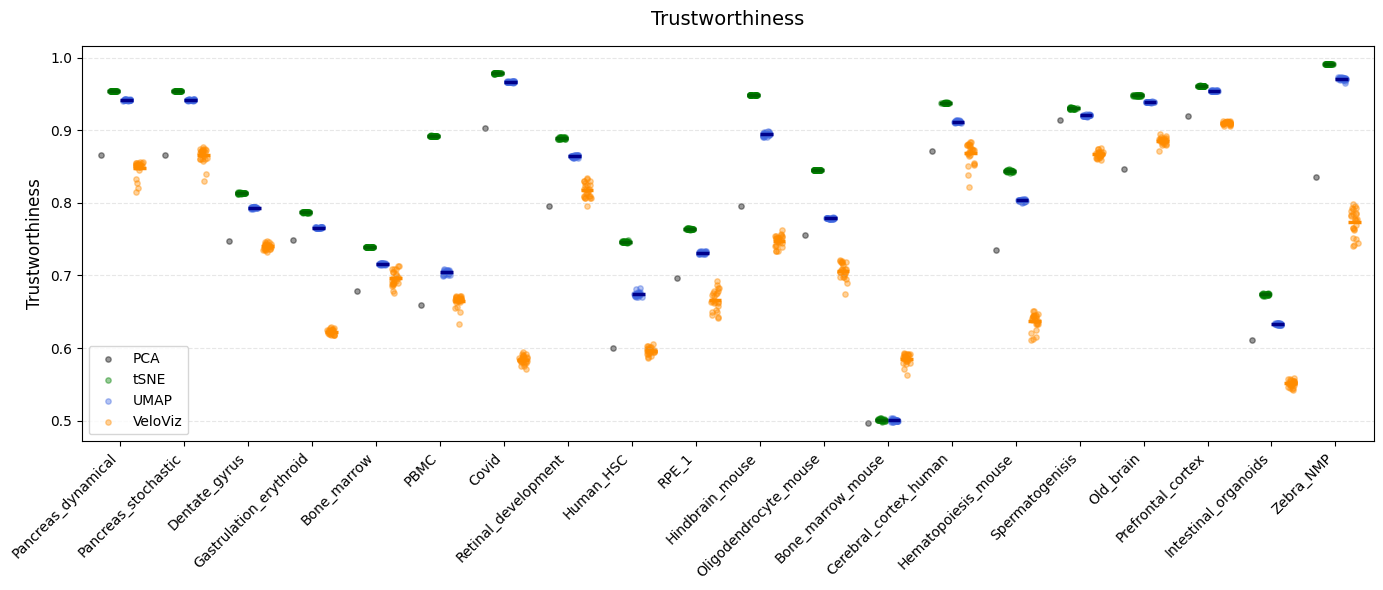

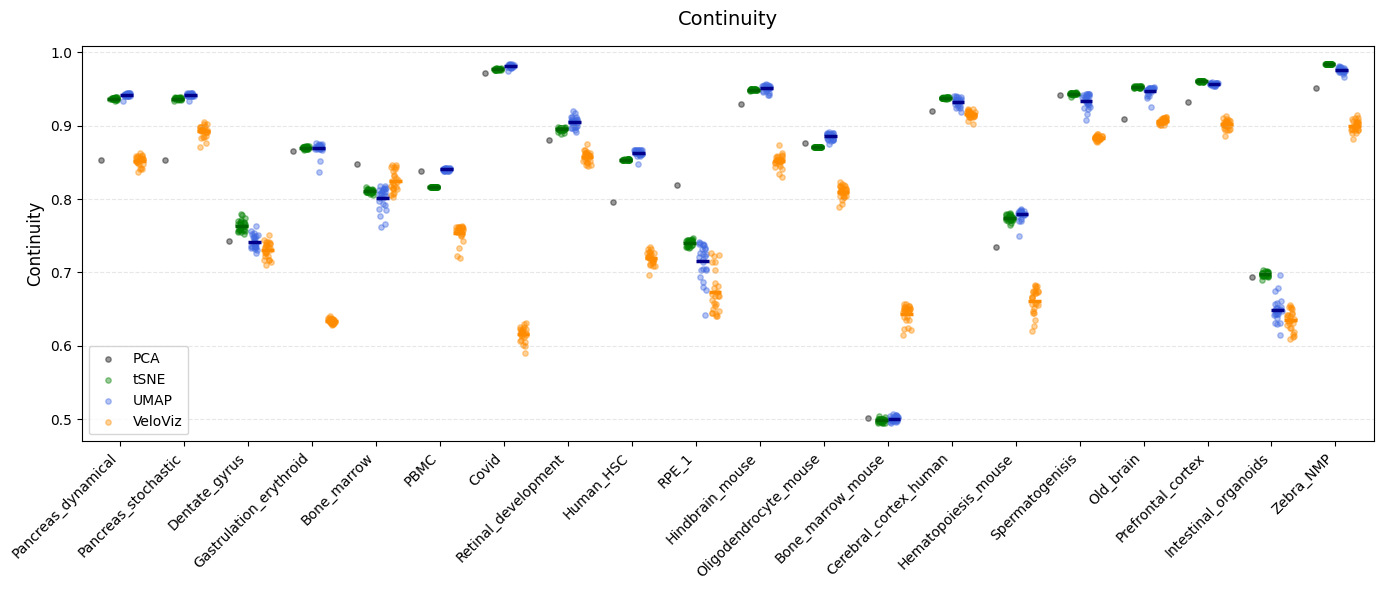

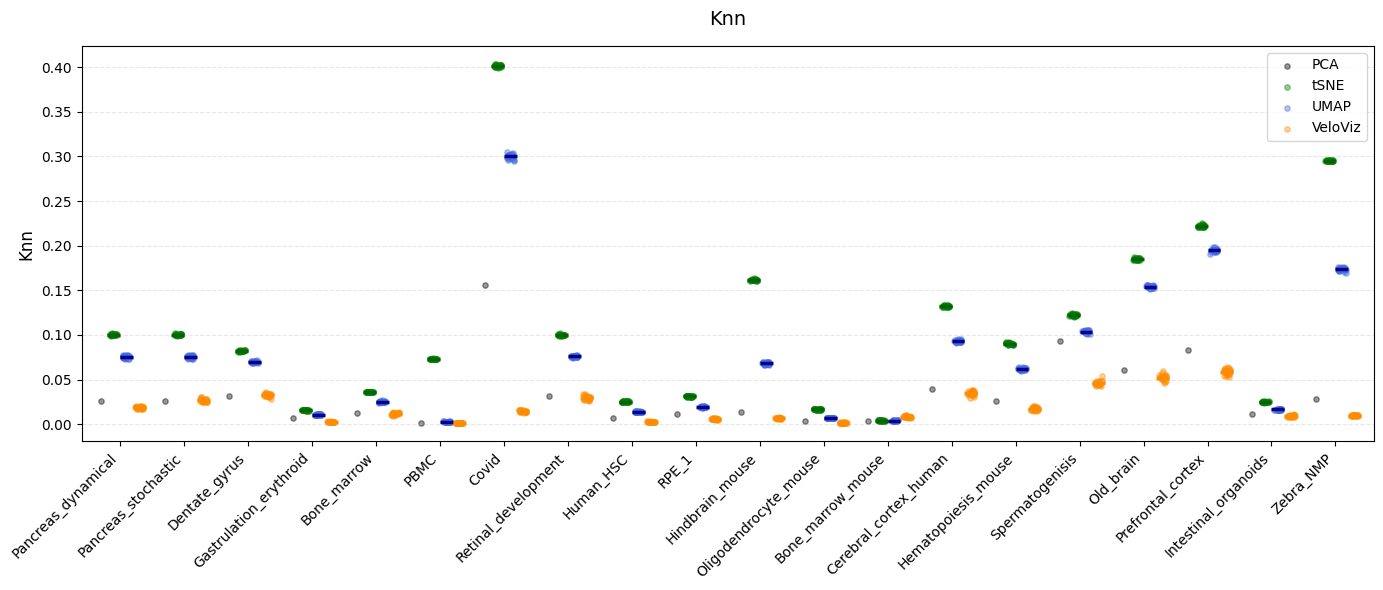

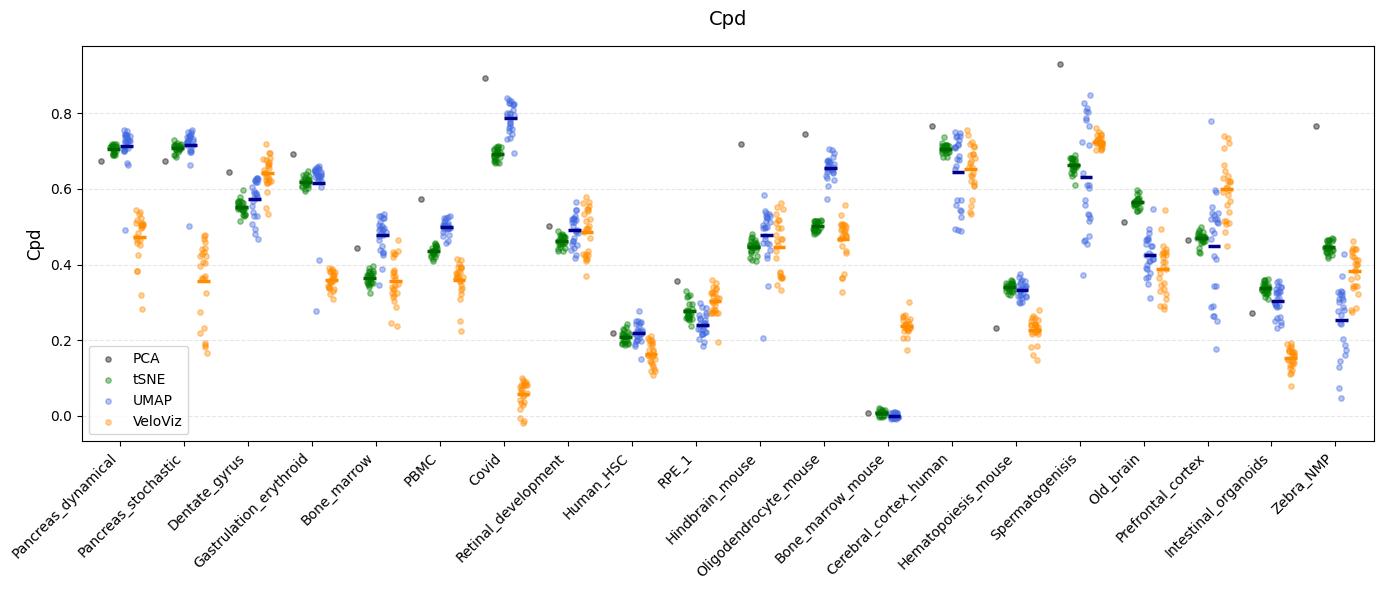

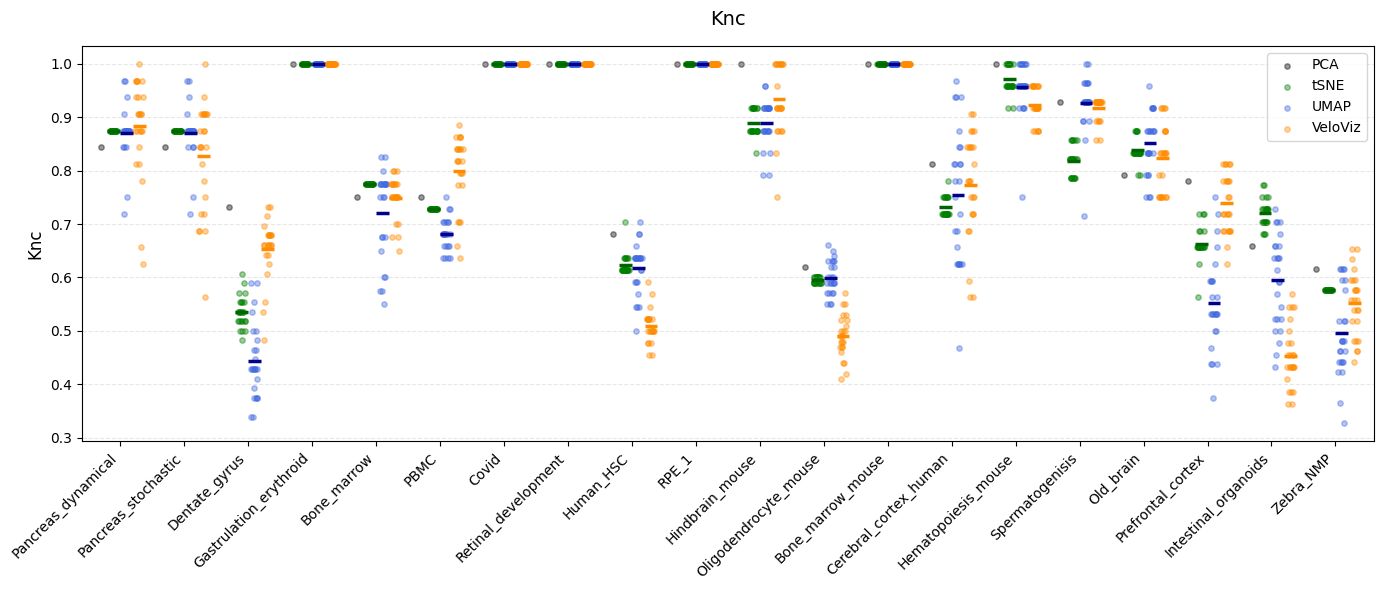

In [5]:
# Define baselines in accordance with the embedding plots 
metrics = ['trustworthiness', 'continuity', 'knn', 'cpd', 'knc']
datasets = df['dataset'].unique()
offsets = {'pca': -0.3, 'tsne': -0.1, 'umap': 0.1, 'veloviz': 0.3}
colors = {'pca': 'black', 'tsne': 'green', 'umap': 'royalblue', 'veloviz': 'darkorange'}

def add_jitter(x_base, arr, width=0.06):
    return x_base + np.random.uniform(-width, width, size=len(arr))

# Generate a separate plot for each metric
for metric in metrics:
    fig, ax = plt.subplots(figsize=(14, 6))
    legend_elements = {}
    
    for i, ds in enumerate(datasets):
        # Subset the dataframe for the current dataset
        ds_data = df[df['dataset'] == ds]

        # --- Plot PCA ---
        pca_vals = ds_data[ds_data['embedding'] == 'pca'][metric].values
        if len(pca_vals) > 0:
            x_pca = i + offsets['pca']
            h_pca = ax.scatter(x_pca, pca_vals, color=colors['pca'], alpha=0.4, s=15)
            
            if 'PCA' not in legend_elements: 
                legend_elements['PCA'] = h_pca
        
        # --- Plot tSNE ---
        tsne_vals = ds_data[ds_data['embedding'] == 'tsne'][metric].values
        if len(tsne_vals) > 0:
            x_tsne = i + offsets['tsne']
            h_tsne = ax.scatter(add_jitter(x_tsne, tsne_vals), tsne_vals, color=colors['tsne'], alpha=0.4, s=15)
            # Add mean line
            ax.hlines(np.mean(tsne_vals), x_tsne-0.1, x_tsne+0.1, color='darkgreen', linewidth=2.5)
            
            if 'tSNE' not in legend_elements: 
                legend_elements['tSNE'] = h_tsne

        # --- Plot UMAP ---
        umap_vals = ds_data[ds_data['embedding'] == 'umap'][metric].values
        if len(umap_vals) > 0:
            x_umap = i + offsets['umap']
            h_umap = ax.scatter(add_jitter(x_umap, umap_vals), umap_vals, color=colors['umap'], alpha=0.4, s=15)
            # Add mean line
            ax.hlines(np.mean(umap_vals), x_umap-0.1, x_umap+0.1, color='darkblue', linewidth=2.5)
            
            if 'UMAP' not in legend_elements: 
                legend_elements['UMAP'] = h_umap

        # --- Plot Veloviz ---
        velo_vals = ds_data[ds_data['embedding'] == 'veloviz'][metric].values
        if len(velo_vals) > 0:
            x_velo = i + offsets['veloviz']
            h_velo = ax.scatter(add_jitter(x_velo, velo_vals), velo_vals, color=colors['veloviz'], alpha=0.4, s=15)
            # Add mean line
            ax.hlines(np.mean(velo_vals), x_velo-0.1, x_velo+0.1, color='darkorange', linewidth=2.5)
            
            if 'VeloViz' not in legend_elements: 
                legend_elements['VeloViz'] = h_velo

    # --- Formatting the plot ---
    ax.set_xticks(range(len(datasets)))
    ax.set_xticklabels(datasets, rotation=45, ha='right', fontsize=10)
    ax.set_xlim(-0.6, len(datasets) - 0.4)
    
    ax.grid(True, axis='y', alpha=0.3, linestyle='--')
    ax.set_ylabel(metric.capitalize(), fontsize=12)
    ax.set_title(f"{metric.capitalize()}", fontsize=14, pad=15)
    
    ax.legend(legend_elements.values(), legend_elements.keys())
    
    plt.tight_layout()
    # plt.savefig(f"results/{metric}_UMAP_TSNE.pdf", transparent=True)
    plt.show()